# Лабораторная работа 1. Иерархический кластерный анализ. Хугаев Артем

Данные: 48 городов, 1991 год.

- City (Город): Название города

- Работа (Work): Взвешенное среднее числа рабочих часов, сосчитанное по 12
профессиям

- Цена (Price): Индекс цен 112 товаров и услуг, включая арендную плату за
жилье(значение для Цюриха взято за 100%)

- Заработная плата (Salary): Индекс заработной платы за час работы,
сосчитанный по 12 профессиям после налогов и вычетов (значение для Цюриха
взято за 100%)

In [2]:
# Библиотеки + Читаем файл

%pip -q install gdown

import gdown
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')

file_id = "1tzLHiEN1BqvjlJaeQToBn0F69n-OQ-0W"


gdown.download(id=file_id, output="Econom_Cities_data.csv", quiet=False)

df = pd.read_csv("Econom_Cities_data.csv", sep=";")

Downloading...
From: https://drive.google.com/uc?id=1tzLHiEN1BqvjlJaeQToBn0F69n-OQ-0W
To: /content/Econom_Cities_data.csv
100%|██████████| 1.18k/1.18k [00:00<00:00, 1.24MB/s]


## Предобработка данных

In [3]:
print(df) # проблема: пропущенные значения у городов Cairo и Jakarta заменяются на -9999 --> это искажает подсчет расстояния

              City  Work  Price Salary
0        Amsterdam  1714   65,6     49
1           Athens  1792   53,8   30,4
2           Bogota  2152   37,9   11,5
3           Bombay  2052   30,3    5,3
4         Brussels  1708   73,8   50,5
5     Buenos_Aires  1971   56,1   12,5
6            Cairo -9999   37,1  -9999
7          Caracas  2041     61   10,9
8          Chicago  1924   73,9   61,9
9       Copenhagen  1717   91,3   62,9
10          Dublin  1759     76   41,4
11      Dusseldorf  1693   78,5   60,2
12       Frankfurt  1650   74,5   60,4
13          Geneva  1880   95,9   90,3
14        Helsinki  1667  113,6   66,6
15       Hong_Kong  2375   63,8   27,8
16         Houston  1978   71,9   46,3
17         Jakarta -9999   43,6  -9999
18    Johannesburg  1945   51,1     24
19    Kuala_Lumpur  2167   43,5    9,9
20           Lagos  1786   45,2    2,7
21          Lisbon  1742   56,2   18,8
22          London  1737   84,2   46,2
23     Los_Angeles  2068   79,8   65,2
24      Luxembourg  1768 

In [4]:
df.dtypes # проблема Price и Salary имеют тип object

,0
City,object
Work,int64
Price,object
Salary,object


In [5]:
# приведем переменные к числовым значениям
cols = ['Work', 'Price', 'Salary']

for col in cols:
  df[col] = pd.to_numeric(df[col].astype("string").str.strip().str.replace(",", ".", regex=False))

df[cols].dtypes

,0
Work,Int64
Price,Float64
Salary,Float64


In [7]:
# Сначала na вместо пропусков

df['Work'] = df['Work'].replace(-9999, float("nan"))
df['Salary'] = df['Salary'].replace(-9999, float("nan"))

# Заменим медианой пропущенные значения
df[cols] = df[cols].fillna(df[cols].median())

print(df)

              City  Work  Price  Salary
0        Amsterdam  1714   65.6    49.0
1           Athens  1792   53.8    30.4
2           Bogota  2152   37.9    11.5
3           Bombay  2052   30.3     5.3
4         Brussels  1708   73.8    50.5
5     Buenos_Aires  1971   56.1    12.5
6            Cairo  1849   37.1   43.65
7          Caracas  2041   61.0    10.9
8          Chicago  1924   73.9    61.9
9       Copenhagen  1717   91.3    62.9
10          Dublin  1759   76.0    41.4
11      Dusseldorf  1693   78.5    60.2
12       Frankfurt  1650   74.5    60.4
13          Geneva  1880   95.9    90.3
14        Helsinki  1667  113.6    66.6
15       Hong_Kong  2375   63.8    27.8
16         Houston  1978   71.9    46.3
17         Jakarta  1849   43.6   43.65
18    Johannesburg  1945   51.1    24.0
19    Kuala_Lumpur  2167   43.5     9.9
20           Lagos  1786   45.2     2.7
21          Lisbon  1742   56.2    18.8
22          London  1737   84.2    46.2
23     Los_Angeles  2068   79.8    65.2


## Стандартизуем данные

Это необходимо так как данные не в одной шкале, что может влиять на расчет расстояния между точками

In [8]:
all_cols = ["Work", "Price", "Salary"]

df_scaled = (df[all_cols] - df[all_cols].mean()) / df[all_cols].std(ddof=1)

In [9]:
print(df_scaled)

        Work     Price    Salary
0  -0.964372 -0.149666  0.382985
1  -0.507448 -0.691331 -0.384361
2   1.601428 -1.421203 -1.164083
3   1.015629 -1.770072 -1.419865
4   -0.99952  0.226746  0.444868
5   0.541132 -0.585752 -1.122828
6  -0.173543 -1.457926   0.16227
7   0.951191 -0.360823 -1.188836
8   0.265806  0.231336  0.915177
9  -0.946798  1.030064  0.956432
10 -0.700762  0.327734  0.069446
11  -1.08739  0.442494  0.845043
12 -1.339283  0.258879  0.853294
13  0.008055  1.241221  2.086824
14 -1.239697   2.05372  1.109076
15   2.90776 -0.232293 -0.491624
16  0.582138  0.139529  0.271596
17 -0.173543 -1.159551   0.16227
18  0.388824 -0.815272 -0.648394
19  1.689298 -1.164141 -1.230091
20 -0.542596 -1.086105 -1.527129
21 -0.800348 -0.581162  -0.86292
22 -0.829638  0.704146  0.267471
23  1.109357  0.502169  1.051319
24  -0.64804  0.102806  1.294724
25 -0.987804  1.144823  0.424241
26  2.280955 -1.324805 -1.473497
27  0.382966 -0.874947 -1.403363
28  -0.61875  0.603158  0.560383
29 -0.3024

## Кластеризация

Делаем два выбора

1) Как измерять расстояние между кластерами --> Метод Уорда

2) Как измерять расстояние между точками --> Евклидово расстояние

Обоснование выбора:

1) Метод Уорда объединяет ту пару кластеров для которой прирост WCSS минимальный. Это соответствует цели, что внутри группы города должны относительно мало различаться по стандартизованным Work, Price и Salary

2) Метод Уорда математически связан именно с евклидовой метрикой. В SciPy сочетать ward с произвольной другой метрикой некорректно.


In [10]:
link = linkage(df_scaled, 'ward', 'euclidean')

In [11]:
print(type(link))
print(link.shape)

<class 'numpy.ndarray'>
(47, 4)


Наибольший прирост WCSS происходит при объединении из 2 кластеров в 1.

2 - потенциально лучший выбор для кол.ва кластеров

In [12]:
link

array([[22.        , 35.        ,  0.12680338,  2.        ],
       [28.        , 46.        ,  0.2054363 ,  2.        ],
       [27.        , 30.        ,  0.23514259,  2.        ],
       [ 7.        , 39.        ,  0.26535806,  2.        ],
       [ 2.        , 19.        ,  0.2795691 ,  2.        ],
       [ 4.        , 41.        ,  0.27969137,  2.        ],
       [ 6.        , 17.        ,  0.29837511,  2.        ],
       [ 8.        , 45.        ,  0.31083904,  2.        ],
       [11.        , 12.        ,  0.31182223,  2.        ],
       [ 1.        , 32.        ,  0.34384059,  2.        ],
       [20.        , 36.        ,  0.39125096,  2.        ],
       [ 0.        , 53.        ,  0.41116386,  3.        ],
       [10.        , 48.        ,  0.44552294,  3.        ],
       [13.        , 47.        ,  0.44777564,  2.        ],
       [38.        , 57.        ,  0.48244469,  3.        ],
       [14.        , 33.        ,  0.51386251,  2.        ],
       [ 9.        , 25.

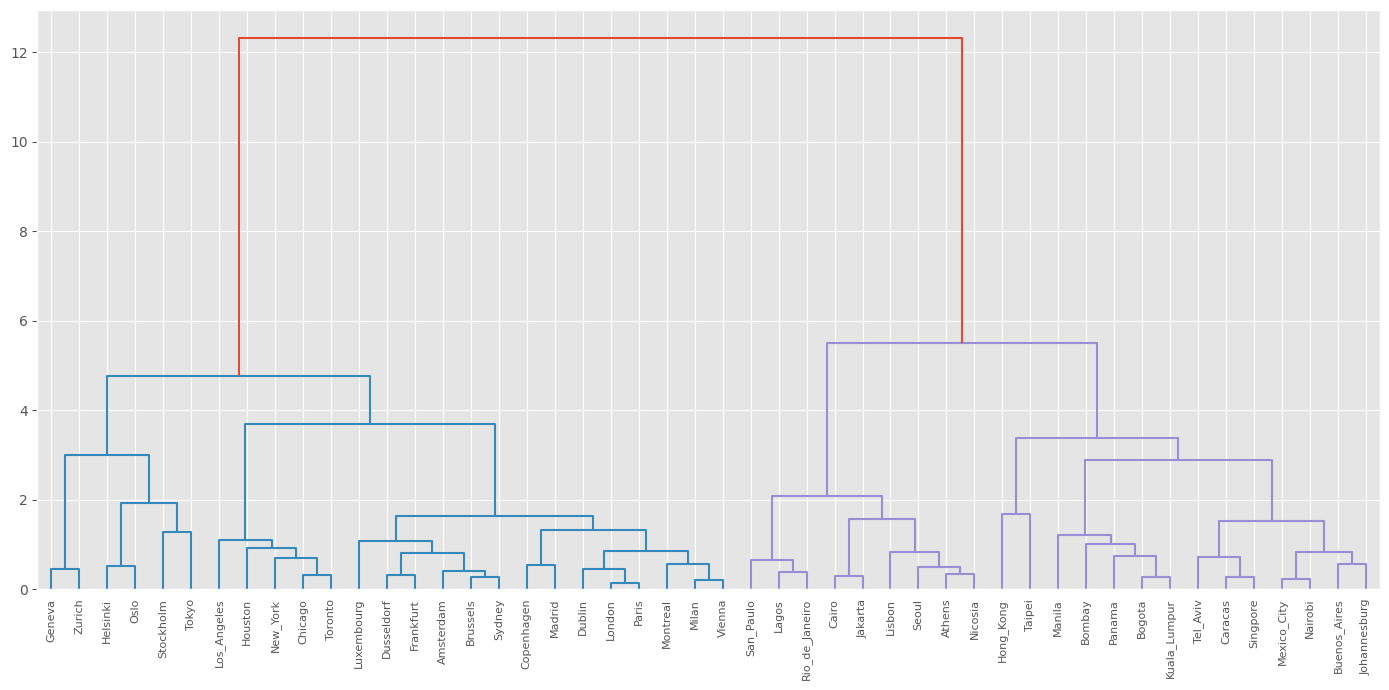

In [13]:
fig = plt.figure(figsize=(14, 7))

dn = dendrogram(link, color_threshold=8, labels=df["City"].tolist(),leaf_rotation=90,leaf_font_size=8) # порог раскраски - 8

plt.tight_layout()
plt.show()

In [14]:
df["Cluster"] = fcluster(link, 2, criterion="maxclust")

display(df.sort_values("Cluster"))

,City,Work,Price,Salary,Cluster
0,Amsterdam,1714,65.6,49.0,1
4,Brussels,1708,73.8,50.5,1
13,Geneva,1880,95.9,90.3,1
12,Frankfurt,1650,74.5,60.4,1
11,Dusseldorf,1693,78.5,60.2,1
10,Dublin,1759,76.0,41.4,1
9,Copenhagen,1717,91.3,62.9,1
8,Chicago,1924,73.9,61.9,1
14,Helsinki,1667,113.6,66.6,1
25,Madrid,1710,93.8,50.0,1


In [15]:
df.groupby("Cluster")[["Work", "Price", "Salary"]].agg(["mean", "count"])

Work            Price           Salary      
                mean count       mean count       mean count
Cluster                                                     
1            1789.24    25     84.972    25     59.032    25
2        1975.782609    23  51.347826    23  18.721739    23

Содержательная интерпритация:

Кластер 1 - в основном Европейские и Американские крупные города (+ Токио и Сидней), с высокими ценами и зарплатами, чуть меньшим кол.вом рабочих часов чем в городах Кластера 2

Кластер 2 - крупные города развивающихся стран, где меньше цены и зарплаты

Экономически кластеризация вышла довольно логичной

## Какое еще количество Кластеров возможно?

Метод локтя

Text(0, 0.5, 'Высота объединения')

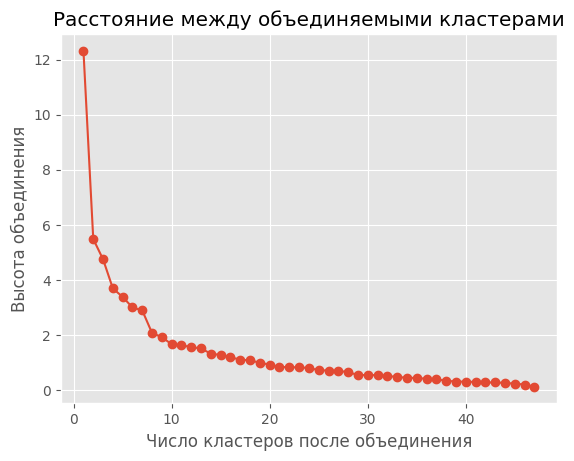

In [16]:
dist = link[:, 2]
dist_rev = dist[::-1]
idxs = range(1, len(dist) + 1)
plt.plot(idxs, dist_rev, marker='o')
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Число кластеров после объединения')
plt.ylabel('Высота объединения')

Также видим, что кроме 2 кластеров 8 тоже может быть потенциально полезно проверить, так как это последнее ощутимое изменение высоты при объединении

## 8 Кластеров

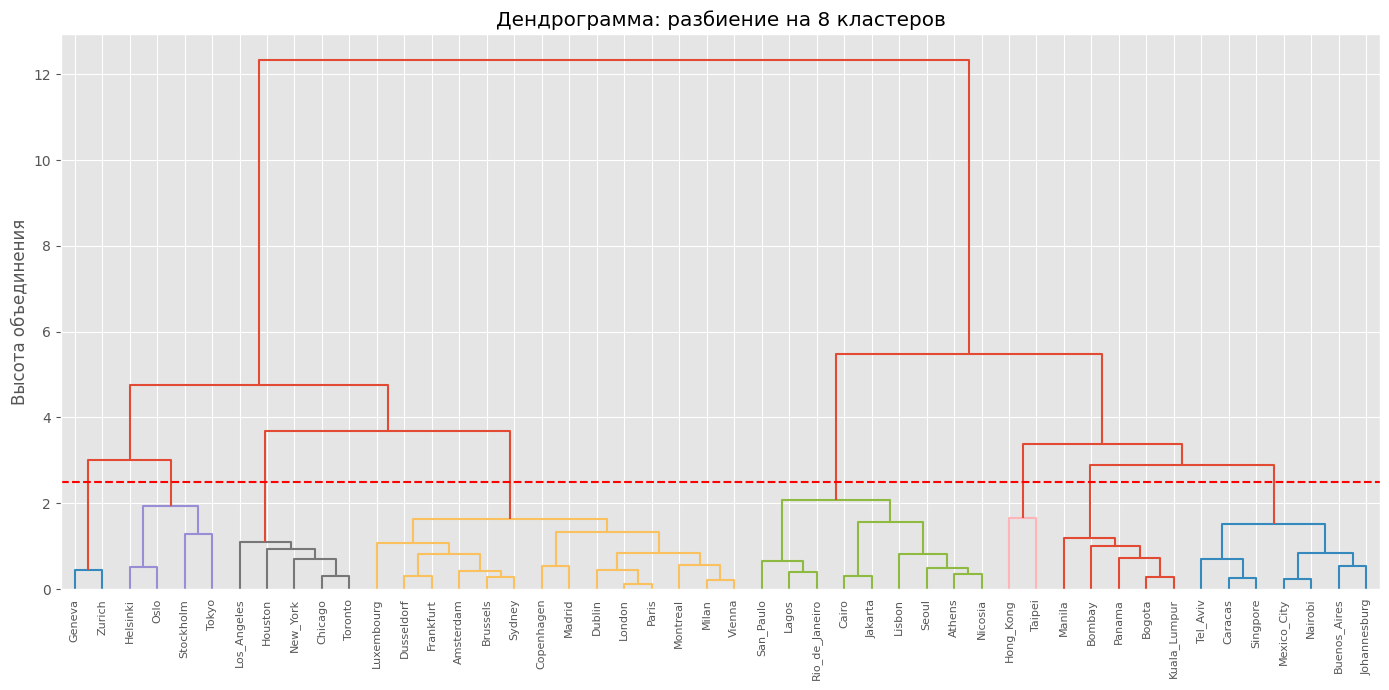

In [18]:
plt.figure(figsize=(14, 7))

dendrogram(link, color_threshold= 2.5, labels=df["City"].tolist(), leaf_rotation=90, leaf_font_size=8)

plt.axhline(y= 2.5, color="red", linestyle="--")
plt.title("Дендрограмма: разбиение на 8 кластеров")
plt.ylabel("Высота объединения")
plt.tight_layout()
plt.show()

In [19]:
df["Cluster"] = fcluster(link, 8, criterion="maxclust")

display(df.sort_values("Cluster"))

,City,Work,Price,Salary,Cluster
13,Geneva,1880,95.9,90.3,1
47,Zurich,1868,100.0,100.0,1
33,Oslo,1583,115.5,63.7,2
14,Helsinki,1667,113.6,66.6,2
44,Tokyo,1880,115.0,68.0,2
40,Stockholm,1805,111.3,39.2,2
8,Chicago,1924,73.9,61.9,3
16,Houston,1978,71.9,46.3,3
23,Los_Angeles,2068,79.8,65.2,3
31,New_York,1942,83.3,65.8,3


In [20]:
df.groupby("Cluster")[["Work", "Price", "Salary"]].agg(["mean", "count"])

Work            Price           Salary      
            mean count       mean count       mean count
Cluster                                                 
1         1874.0     2      97.95     2      95.15     2
2        1733.75     4     113.85     4     59.375     4
3         1960.0     5      75.82     5      59.48     5
4         1732.0    14  78.135714    14  53.614286    14
5         1810.0     9  48.588889     9  24.644444     9
6         2260.0     2      74.05     2      31.15     2
7         2143.4     5      40.18     5        8.9     5
8         1988.0     7  56.385714     7  14.571429     7

Содержательная интерпретация:

| Кластер | Городов | Work | Price | Salary | Возможная интерпретация |
|---|---:|---:|---:|---:|---|
| **1** | 2 | 1874 | 98,0 | 95,2 | **Наиболее высокая почасовая зарплата при высоких ценах.** Женева и Цюрих выделяются прежде всего зарплатой. |
| **2** | 4 | 1734 | 113,9 | 59,4 | **Самые высокие цены при относительно небольшом рабочем времени.** Зарплата высокая относительно выборки, но существенно ниже швейцарской группы. |
| **3** | 5 | 1960 | 75,8 | 59,5 | **Относительно высокая зарплата и более продолжительное рабочее время**, чем в кластерах 2 и 4. Цены ниже, чем в группах 1 и 2. |
| **4** | 14 | 1732 | 78,1 | 53,6 | **Небольшое рабочее время, сравнительно высокая зарплата и умеренные относительно дорогих групп цены.** Самая многочисленная группа. |
| **5** | 9 | 1810 | 48,6 | 24,6 | **Низкие цены и преимущественно невысокие зарплаты при сравнительно небольшом рабочем времени.** Зарплаты внутри группы заметно различаются. |
| **6** | 2 | 2260 | 74,1 | 31,2 | **Наиболее продолжительное рабочее время при промежуточной почасовой зарплате.** Гонконг и Тайбэй отличаются от других групп прежде всего количеством часов. |
| **7** | 5 | 2143 | 40,2 | 8,9 | **Продолжительное рабочее время, самые низкие средние цены и зарплаты.** |
| **8** | 7 | 1988 | 56,4 | 14,6 | **Невысокая зарплата и относительно низкие цены**, но цены и зарплаты выше, а рабочее время меньше, чем в кластере 7. |

## Сколько кластеров выбрать?

Содержательно: зависит до какого уровня детализации мы хотим дойти так как переменных не очень много то кажется что сложно обосновывать различия когда кластеров много.

Решение с 2 кластерами по логике обоснования - кажется наиболее понятным с точки зрения логики разделения городов

Проверка с помощью метрики силуэта

Силуэт - насколько объект похож на свою группу по сравнению с ближайшей другой группой

Силуэт для объекта $i$:

$$
s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}
$$

- $a(i)$ — среднее расстояние до остальных объектов своего кластера.
- $b(i)$ — минимальное среднее расстояние до объектов другого кластера.

Средний силуэт по всем объектам:

$$
S = \frac{1}{n}\sum_{i=1}^{n}s(i)
$$

,cluster,silhouette
0,2,0.453744
1,3,0.363824
2,4,0.354729
3,5,0.350967
4,6,0.364685
5,7,0.393956
6,8,0.387529
7,9,0.383236
8,10,0.394779


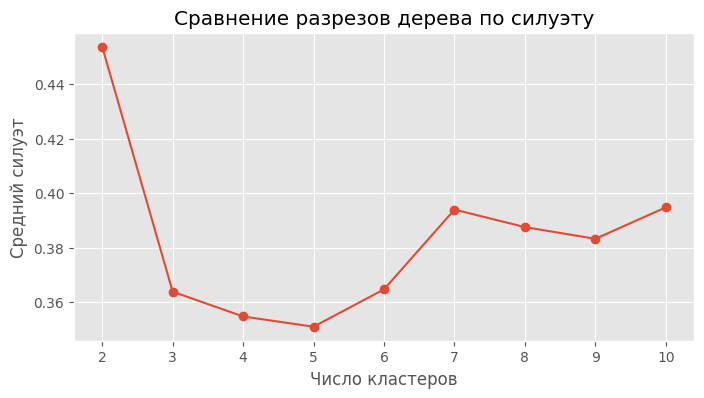

In [21]:
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import silhouette_score

results = []

for cluster in range(2, 11):
    labels = fcluster(link, t=cluster, criterion="maxclust")

    score = silhouette_score(df_scaled,labels, metric="euclidean")

    results.append({ "cluster": cluster, "silhouette": score})

scores = pd.DataFrame(results)
display(scores)

plt.figure(figsize=(8, 4))
plt.plot(scores["cluster"], scores["silhouette"], marker="o")
plt.xticks(scores["cluster"])
plt.xlabel("Число кластеров")
plt.ylabel("Средний силуэт")
plt.title("Сравнение разрезов дерева по силуэту")
plt.show()

Максимальный силуэт получен при k=2 : 0,453744.

## Насколько разбиение бы изменилось, если бы мы не заменяли на медиану а удалили NA

Adjusted Rand Index

$$
ARI = \frac{RI - \mathbb{E}[RI]}{1 - \mathbb{E}[RI]}
$$

где $RI$ — индекс Рэнда, а $\mathbb{E}[RI]$ — его ожидаемое значение
при случайных разбиениях с сохранением размеров кластеров.

In [22]:
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import adjusted_rand_score

cols = ["Work", "Price", "Salary"]
mask = ~df["City"].isin(["Cairo", "Jakarta"])
df_check = df.loc[mask].copy()

# Исходное разбиение
labels_before = fcluster(link, t=2, criterion="maxclust")[mask.to_numpy()]

# Заново стандартизуем и кластеризуем без двух городов
X_check = (df_check[cols] - df_check[cols].mean()) / df_check[cols].std(ddof=1)
link_check = linkage(X_check, method="ward", metric="euclidean")
labels_after = fcluster(link_check, t=2, criterion="maxclust")

# Сравниваем разбиения
ari = adjusted_rand_score(labels_before, labels_after)
print(f"ARI: {ari:.2f}")

display(pd.crosstab(labels_before,labels_after, rownames=["Исходный кластер"], colnames=["Кластер без Cairo и Jakarta"]))

ARI: 1.00


Кластер без Cairo и Jakarta,1,2
Исходный кластер,,
1,25,0
2,0,21


ARI = 1: разделение оставшихся 46 городов на две группы сохранилось после исключения Cairo и Jakarta и повторной стандартизации.

## Вывод

Для измерения расстояния между кластерами использовал: Метод Уорда

Для определения расстояния между городами: евклидово расстояние.

Лучшим решением было выбрано разбиение на два кластера. Выбор подтверждается скачком высоты объединения и максимальным средним силуэтом среди проверенных вариантов - 0,454. А также понятной интерпритацией.

Первая группа характеризуется более высокими ценами и почасовой зарплатой при меньшем рабочем времени (города в развитых странах на то время), вторая - противоположным сочетанием показателей (города из развивающихся стран).

Разбиение на восемь кластеров даёт дополнительную детализацию, но имеет меньший силуэт - 0,388. После исключения Cairo и Jakarta разбиение остальных городов на две группы сохранилось (ARI = 1). Принадлежность самих этих двух городов следует трактовать осторожно из-за заполнения пропусков медианами.